# Convolutional Neural Network with CIFAR100 Dataset

**Model Architecture**

This model uses convolutional layers in its architecture. Convolutional layers apply a kernel (say, a 3x3 matrix) at each pixel of an image to identify edges (and the core shape of an image). This helps classifying images with lot of features.

**Dataset**

The training is performed on CIFAR-100 dataset (Canadian Institute for Advanced Research, 100 classes). This is one of the datasets built into PyTorch/torchVision framework. These built-in datasets are subclasses of `torch.utils.data.Dataset` class. So, it is easy to apply transformations from `transforms` and use with the `DataLoader` class to create batches of samples (images here) for the training loop.

This dataset can also be downloaded from Hugging Face at [CIFAR100 Dataset](https://huggingface.co/datasets/uoft-cs/cifar100). On this site there is a Dataset Viewer to get an idea of what images are there in this dataset. It also has the link to the original paper that used this dataset from 2009.

This dataset has 60,000 images of size 32x32 pixels. These images are grouped into 20 superclasses (e.g. aquatic mammals, fish, flowers, etc.). Each superclass has 5 classes (e.g. orchids, poppies, rose, sunflowers, and tulips classes in the flowers superclass).

## 1. Imports

**1.1 PyTorch Primary**

For training a model, following 3 modules are foundational:

- `torch`: main PyTorch library/module. This contains base functionality like Tensors, etc.
- `torch.nn`: the neural network module. It contains classes for different types of layers, including nn.Linear, nn.Conv2d, etc.
- `torch.optim`: the optimizer module. Includes several optimizers, including SGD and Adam optimizers.

**1.2 PyTorch Data and Preparation**

For data management and preparation, following modules/classes are used:

- `transforms`: has several transformation classes; for example, converting image data tensors, transforming the existing images slightly so as to provide new samples in the training loop.
- `DataLoader`: provides the images to the training loop in small batches; samples are read from the underlying Dataset. Batch size can be set to accomodate the amount of memory available on the training hardware and the samples can be shuffled to provide different order during training.

**1.3 System Related**
Following support modules are imported:
- `os`: for path/folder related functionality

**1.4 Third-party Utils**
- `PIL.Image`: For dealing with the image files in this dataset
- `display`: For displaying an image

In [377]:
# PyTorch Primary
import torch
import torch.nn as nn
import torch.optim as optim

# PyTorch Data and Preparation
from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader

# v2 is the latest, however some examples show the legacy version
# In modern systems, only import for v2 should be included
import torchvision.transforms as transforms
import torchvision.transforms.v2 as v2

# System Related
import os

# Third-party Utils
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

## 2. Devices for Training

Various devices can be used for the training:

- `cpu`: This is the option if no GPUs are available. This would be the slowest option for training.
- `mps`: This is for Apple GPUs. MPS is Metal Performance Shaders. If the training is being done on a modern Apple Macbook Pro laptop, this is the option.
- `cuda`: If Nvidia GPUs are available, cuda is the option (also AMD via ROCm). Various GPUs are also available for rent from Google Colab. For example, NVidia A100 GPU with standard RAM will provide you with the following GPU:

```
Using Device: cuda
Device Name: NVIDIA A100-SXM4-40GB 
Total Memory: 42405855232 
Compute Capability: 8, 0
```

Typically prototyping of a model is done on machines like local MacBook Pro (with MPS) and full training on CUDA GPUs like A100 according to the size and need for training.

In [378]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"Using Device: {device}")

# Small amount of information is available about the device
if torch.backends.mps.is_available():
    allocated_memory = torch.mps.current_allocated_memory()
    print(f"Current allocated memory on this MPS: {allocated_memory}")

if torch.cuda.is_available():
    i = device.index or 0
    props = torch.cuda.get_device_properties(i)
    print(f"Device Name: {props.name} \nTotal Memory: {props.total_memory} \nCompute Capability: {props.major}, {props.minor}")

Using Device: mps
Current allocated memory on this MPS: 42690816


## 3. Download CIFAR-100 Datafiles

Initializing the CIFAR100 class (a class in the torchvision package), gives you a Dataset that is ready to use for training. During the first time, the data files can be downloaded by setting download=True. Once the data files are downloaded once, there is no need to download these files again and simply use the local data files to initialize a Dataset.

During the first download, a .tar.gz file named `cifar-100-python.tar.gz` will be downloaded. This is about 169MB. Then it will be extracted in to a folder named cifar-100-python with train (155MB) and test (31MB) files separated. These are pickle files.

In [379]:
download = True
if os.path.exists('./data/cifar100'):
    download = False
    print("CIFAR100 Data files exist locally. Using the local dataset.")

ds = CIFAR100(root='./data/cifar100', download=download)

CIFAR100 Data files exist locally. Using the local dataset.


### 3.1 Dataset Base Class

For this dataset, torchvision has a class named `CIFAR100`. The eventual base class for this is `Dataset`, which is called by the `DataLoader` to create batches of images to feed to the training loop in multiple batches.

Here the base classes go like this: CIFAR100 -> CIFAR10 -> VisionDataset -> Dataset

In [380]:
print(f"Base Classes of CIFAR100 to Dataset: \n{CIFAR100.__base__} \n{CIFAR100.__base__.__base__} \n{CIFAR100.__base__.__base__.__base__}")

Base Classes of CIFAR100 to Dataset: 
<class 'torchvision.datasets.cifar.CIFAR10'> 
<class 'torchvision.datasets.vision.VisionDataset'> 
<class 'torch.utils.data.dataset.Dataset'>


### 3.2 Info and a sample from the dataset

The base Dataset class has two methods that will need to be implemented in the derived concrete class; in this case `CIFAR100`. These are `__len__` (which lets you use the builtin len()function) and `__getitem__` (which lets you do easy indexing with dataset[<index>]). These methods will be available in `ds`.

The CIFAR100 class also has two attributes of relevance (whicha are added in the base class CIFAR10):

- classes: a list of classification class strings
- class_to_idx: a dictionary that takes the name of the class as key and returns index

This is a training dataset.
This dataset has 50000 samples.

The target for sample number 101 is 39.
The target class 39 is keyboard.
Image display (keyboard):


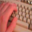

Image info: <PIL.Image.Image image mode=RGB size=32x32 at 0x16D8D2DF0>
Image Type: <class 'PIL.Image.Image'>
Target type: <class 'int'>

Names of 5 classes ending in sample class:
girl
hamster
house
kangaroo
keyboard


In [381]:
# Length of the dataset (number of samples in the dataset)
num_samples = len(ds)
if ds.train:
    print("This is a training dataset.")
else:
    print("This is a test dataset.")
print(f"This dataset has {num_samples} samples.")

# Get a sample from the dataset
sample_number = 101
img, target = ds[sample_number]
class_name = ds.classes[target]
print(f"\nThe target for sample number {sample_number} is {target}.")
print(f"The target class {target} is {class_name}.")

# Display image
print(f"Image display ({class_name}):")
display(img)
print(f"Image info: {img}")
print(f"Image Type: {type(img)}")
print(f"Target type: {type(target)}")

# Names of a few classes
print("\nNames of 5 classes ending in sample class:")
for i in range(max(0, target-4), target+1):
    print(ds.classes[i])

## 4. Converting images to Tensors

The inputs coming out of the above dataset are objects of `PIL.Image.Image` type. For PyTorch training, the image needs to be converted to a Tensor type. The `torchvision.transforms` module provides lot of transformation classes to change the Image input. One of the primary classes is ToTensor(), which converts Image objects into Tensor objects.

In addition, there are classes that are prefixed with Random, which is applied randomly (which takes a parameter for how randomly to apply this transformation). If probabilty of 30% (p=0.3) is passed as an argument, then each image will have a 30% chance that Random transformation applied.

In [382]:
# Classes from torchvision.transforms
print("torchvision.transforms Module:")
print("------------------------------\n")

# A list comprehension that filters out internal and dunder methods
transforms_classes = [name for name in dir(transforms) if not name.startswith("_")]
print("Classes and functions from torchvision.transforms module:\n")

# Prints 5 names per row
for i in range(0, len(transforms_classes), 5):
    row = transforms_classes[i:i + 5]
    print(f"{i+1}-{i+len(row)}: {', '.join(row)}")

# A list comprehension for Random* classes in transforms
transforms_random_classes = [name for name in dir(transforms) if name.startswith("Random")]
print("\nRandom* classes in torchvision.transforms Module: \n(with 'Random' prefix stripped from the class name)\n")

# Prints 5 Random* classes per row
for i in range(0, len(transforms_random_classes), 5):
    row = transforms_random_classes[i:i+5]
    print(f"{i+1}-{i+len(row)}: {', '.join(cls[6:] for cls in row)}")

torchvision.transforms Module:
------------------------------

Classes and functions from torchvision.transforms module:

1-5: AugMix, AutoAugment, AutoAugmentPolicy, CenterCrop, ColorJitter
6-10: Compose, ConvertImageDtype, ElasticTransform, FiveCrop, GaussianBlur
11-15: Grayscale, InterpolationMode, Lambda, LinearTransformation, Normalize
16-20: PILToTensor, Pad, RandAugment, RandomAdjustSharpness, RandomAffine
21-25: RandomApply, RandomAutocontrast, RandomChoice, RandomCrop, RandomEqualize
26-30: RandomErasing, RandomGrayscale, RandomHorizontalFlip, RandomInvert, RandomOrder
31-35: RandomPerspective, RandomPosterize, RandomResizedCrop, RandomRotation, RandomSolarize
36-40: RandomVerticalFlip, Resize, TenCrop, ToPILImage, ToTensor
41-45: TrivialAugmentWide, autoaugment, functional, transforms, v2

Random* classes in torchvision.transforms Module: 
(with 'Random' prefix stripped from the class name)

1-5: AdjustSharpness, Affine, Apply, Autocontrast, Choice
6-10: Crop, Equalize, Erasi

### 4.1 Applying Transformations

Above transformations can be applied to the the images in the dataset. For example, transforms.Grayscale converts the image to gray scale. And a RandomVerticalFlip with a probability of 1 always flips the image vertically.

Original Image (class: telephone):


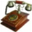

Grayscale Image:


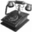

Image Vertically Flipped:


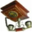

In [383]:
sample_number = 14000
img, target = ds[sample_number]
print(f"Original Image (class: {ds.classes[target]}):")
display(img)

transform_gray = transforms.Grayscale()
img_gray = transform_gray(img)
print(f"Grayscale Image:")
display(img_gray)

transform_flip = transforms.RandomVerticalFlip(p=1.0)
img_jitter = transform_flip(img)
print(f"Image Vertically Flipped:")
display(img_jitter)

### 4.2 Applying ToTensor() transformation to the Dataset

The format for the image coming out of a dataset can be converted Tensor by provide the transformation class during the initialization.

In this case, during the initialization fo CIFAR100 dataset, a transform object `transforms.ToTensor()` is passed into the initializer/constructor. This converts the image into a tensor of shape: (C, H, W), where C is the channel (3 channels: RGB), and Height and Width. This is the format accepted by the nn.Conv2d layer for image tensors.

In [384]:
# Default for train=True, meaning, this is a training set
# Default for download=False, meaning, local data files in the provided folder are used.
ds_t = CIFAR100(root='./data/cifar100', transform=transforms.ToTensor())

# Get a sample from the dataset
sample_number = 12000
img_t, target = ds_t[sample_number]

print("Image Tensor after transforms.ToTensor()")
print("----------------------------------------\n")

print(f"Type of image input: {type(img_t)}")
print(f"Shape of image tensor: {img_t.shape}")
print(f"Min: {img_t.min()}, Max: {img_t.max()}")
print(f"\nA few elements in image tensor: \n{img_t[0:2,0:5, 0:5]}")

Image Tensor after transforms.ToTensor()
----------------------------------------

Type of image input: <class 'torch.Tensor'>
Shape of image tensor: torch.Size([3, 32, 32])
Min: 0.0, Max: 0.8666666746139526

A few elements in image tensor: 
tensor([[[0.7412, 0.7294, 0.7412, 0.7412, 0.7412],
         [0.7451, 0.7294, 0.7373, 0.7451, 0.7412],
         [0.7529, 0.7451, 0.7490, 0.7490, 0.7412],
         [0.7529, 0.7451, 0.7529, 0.7373, 0.7490],
         [0.7569, 0.7451, 0.7608, 0.7490, 0.7569]],

        [[0.6627, 0.6549, 0.6667, 0.6667, 0.6667],
         [0.6706, 0.6549, 0.6667, 0.6706, 0.6667],
         [0.6784, 0.6706, 0.6745, 0.6745, 0.6667],
         [0.6784, 0.6706, 0.6784, 0.6627, 0.6745],
         [0.6784, 0.6706, 0.6863, 0.6745, 0.6784]]])


### 4.3 Shape of original image vs. the transformed tensor

The original image (which is in the format: H x W x C - Height, Width, Channels). This is is the PIL.image.Image format for the original image. This can be converted to an ndarray with np.array(<image>). Shape of this image will be (32, 32, 3) - the channels will be listed last. This is how matplotlib would like the images.

However, ToTensor() changes the shape to C x H x W - putting channels first. If this tensor is passed to matplotlib, it won't be able to show the image. But this tensor can be rearranged with .permute(1, 2, 0), where 0th dimension, that is, Channel can now be moved to last place. Passing this tensor to imshow() in matplotlib will show the image.

ToTensor() does the following:

- Convert the ndarray (the data behind image) to a Tensor
- Reshape the original array from HxWxC to CxHxW
- Change the RGB values from 0-255 to 0-1

Original image and NumPy array
------------------------------

Shape of the original image: (32, 32, 3), dtype: uint8
Min: 3, Max: 255

 A few elements in the original array: 
[[[255 255 255]
  [254 254 254]
  [255 255 255]]

 [[253 253 253]
  [252 252 252]
  [253 253 253]]]

Original Image:


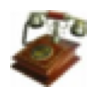


Converted Tensor for PyTorch use
--------------------------------

Shape of the tensor: torch.Size([3, 32, 32]), dtype: torch.float32
min: 0.0117647061124444, Max: 1.0

A few elements from the tensor: 
tensor([[[1.0000, 0.9961, 1.0000],
         [0.9922, 0.9882, 0.9922],
         [0.9961, 0.9922, 0.9961]],

        [[1.0000, 0.9961, 1.0000],
         [0.9922, 0.9882, 0.9922],
         [0.9961, 0.9922, 0.9961]]])

Tensor reshaped with .permute to HxWxC
---------------------------------------

Shape of reshaped tensor: torch.Size([32, 32, 3]), dtype: torch.float32
Image from the reshaped tensor:


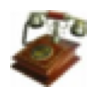

In [385]:
sample_number = 14000

print("Original image and NumPy array")
print("------------------------------")
# Original Image from the non-transformed dataset
img_o, _ = ds[sample_number]

# Convert the image to a NumPy array and print the details
img_o_np = np.array(img_o)
print(f"\nShape of the original image: {img_o_np.shape}, dtype: {img_o_np.dtype}")
print(f"Min: {np.min(img_o)}, Max: {np.max(img_o)}")
print(f"\n A few elements in the original array: \n{img_o_np[0:2, 0:3]}")

print("\nOriginal Image:")
fig, ax = plt.subplots(figsize=(1,1))
ax.axis("off")
ax.imshow(img_o_np)
plt.show()

print("\nConverted Tensor for PyTorch use")
print("--------------------------------")

img_t, _ = ds_t[sample_number]
print(f"\nShape of the tensor: {img_t.shape}, dtype: {img_t.dtype}")
print(f"min: {img_t.min()}, Max: {img_t.max()}")
print(f"\nA few elements from the tensor: \n{img_t[0:2,0:3,0:3]}")

print("\nTensor reshaped with .permute to HxWxC")
print("---------------------------------------")
img_tp = img_t.permute(1, 2, 0)
print(f"\nShape of reshaped tensor: {img_tp.shape}, dtype: {img_tp.dtype}")

print("Image from the reshaped tensor:")
fig, ax = plt.subplots(figsize=(1,1))
ax.axis("off")
ax.imshow(img_tp)
plt.show()

### 4.4 Mean and Standard Deviation

To normalize the values (for training), we need mean and standard deviation of the values in the 3 channels of the images (RGB). For this do the following:

- **Stack the images**

Stack all the image tensors. So, the resulting tensor will be of shape: C x H x W x N
CHW are the Channels, Height, and Width that make up a single image.

For 50,000 training images, the resulting tensor shape is: (3, 32, 32, 50000)

- **Create a view with 3 columns**

.view(3, -1) reshapes the stacked tensor into 3 columns and however many rows (-1 says calculate the number of rows with 3 as first part of the shape).

This resulting tensor will be of shape: (3, {a large number}). Here the RGB values are arranged in 3 columns.

- **Calculate mean/std along the columns**

We need 3 means and 3 stds for the 3 columns, which are RGB. So, we caluclate mean/std along the dimension 1 (which is the column; dimension 0 is the number of rows, which is large - one per pixel)

In [386]:
print("Calculate mean and standard deviation")
print("-------------------------------------\n")

# Stack the all the images in the dataset
img_stack = torch.stack(tensors=[img_t for img_t, _ in ds_t], dim=3)
print(f"Shape of the stacked image tensors: {img_stack.shape}")

# Reshape the underlying data to 3x<pixel count>.
img_stack_rgb = img_stack.view(3, -1)
print(f"Shape of the RGB(3 channel)tensor: {img_stack_rgb.shape}")

# Calculate mean, std for 3 channels along Dimension 1
# First column will have 51.2million values for R
# Second column for G and third for B
# Mean, std needs to be calculated for these columns, which dimension 1
cifar100_mean = img_stack_rgb.mean(dim=1)
cifar100_std = img_stack_rgb.std(dim=1)

print(f"\nFor CIFAR100 Training Dataset: \
      \nmean = {cifar100_mean} \
      \nStandard Deviation = {cifar100_std}")

Calculate mean and standard deviation
-------------------------------------

Shape of the stacked image tensors: torch.Size([3, 32, 32, 50000])
Shape of the RGB(3 channel)tensor: torch.Size([3, 51200000])

For CIFAR100 Training Dataset:       
mean = tensor([0.5071, 0.4865, 0.4409])       
Standard Deviation = tensor([0.2673, 0.2564, 0.2762])


### 4.5 Transormations for Training and Validation

Both training and validation datasets need to go through two transormations: converting the image arrays to tensors (with .ToTensor) and normalization with mean and std (with .Normalize(mean, std)).

For training dataset, before the above transformations, we can apply other transformations to change the image slightly so that the model sees the same images in a slightly different way (a rotated image, a flipped image, etc.)

In [387]:
standard_transform = [
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=cifar100_mean, std=cifar100_std),
]

augment_transform = [
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(15),
]

train_transform = v2.Compose(augment_transform + standard_transform)
val_transform = v2.Compose(standard_transform)

In [388]:
ds_train = CIFAR100(root='./data/cifar100', 
                    train=True, 
                    transform=train_transform)

ds_val = CIFAR100(root='./data/cifar100',
                  train=False,
                  transform=val_transform)

In [389]:
print(len(ds_train))
print(len(ds_val))

50000
10000


In [390]:
batch_size = 64

dl_train = DataLoader(dataset=ds_train,
                      batch_size=batch_size,
                      shuffle=True)
dl_val = DataLoader(dataset=ds_val,
                    batch_size=batch_size,
                    shuffle=False)

## 5. A Model with Convolutional Layers

Following is a model with 3 groups of nn.Conv2d, nn.ReLU, and nn.MaxPool2d layers. Output from these layers is flattened and fed to linear layers to get a final classification.

In [540]:
class ModelCNN(nn.Module):
    def __init__(self, num_classes):
        super(ModelCNN, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(128 * 4 * 4, 512)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [541]:
model = ModelCNN(100)
print(f"Info on Model: \n{model}")

Info on Model: 
ModelCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=100, bias=True)
)


### 5.1 First Convolutional Layer

In this example, one image (just one image) from the dataset is fed to a convolutional layer.

In [551]:
print("Processing on the First Convolutional Layer:")
print("=============================================")

torch.manual_seed(42)

print("\nOne Image (input)")
print("-----------------\n")
# Get one image
sample_number = 14000
img, target = ds_train[sample_number]
print(f"One image shape (RGB, HxW): {img.shape}")

# Convolutional layer takes a 4D tensor
# For one image: (1, 3, 32, 32) - (N, C, H, W)
# Unsqueeze on dimension 0 and give 1 on dim0
img = img.unsqueeze(0)
print(f"Unsqueezed image tensor shape (input for conv layer): {img.shape}")


print("\n\nConvolutional Layer")
print("-------------------\n")
# The first convolutional layer from the model
conv_layer1 = model.conv1
print(f"Info on conv1 layer: {conv_layer1}")

# Weights and biases
print(f"Shape of the weights on conv layer1: {conv_layer1.weight.shape}")
print(f"Shape of the biases on conv layer1: {conv_layer1.bias.shape}")

# Number of parameters at this layer: weights + biases
num_weights = conv_layer1.weight.numel()
num_biases = conv_layer1.bias.numel()
# num parameters: num_weights + num_biases
num_params = sum(p.numel() for p in conv_layer1.parameters())
print(f"\nNum weights: {num_weights}, Num Biases: {num_biases}, Total Params: {num_params}")

weight_kernel = conv_layer1.weight[0]
print(f"\nOne (3x3) of the weight kernel for 3 channels (3x3x3): \n{weight_kernel[0]}")
bias = conv_layer1.bias[0]
print(f"One bias: {bias}")

Processing on the First Convolutional Layer:

One Image (input)
-----------------

One image shape (RGB, HxW): torch.Size([3, 32, 32])
Unsqueezed image tensor shape (input for conv layer): torch.Size([1, 3, 32, 32])


Convolutional Layer
-------------------

Info on conv1 layer: Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Shape of the weights on conv layer1: torch.Size([32, 3, 3, 3])
Shape of the biases on conv layer1: torch.Size([32])

Num weights: 864, Num Biases: 32, Total Params: 896

One (3x3) of the weight kernel for 3 channels (3x3x3): 
tensor([[-0.1054, -0.0800,  0.0843],
        [ 0.1284,  0.0382, -0.1475],
        [-0.1499,  0.1055,  0.0474]], grad_fn=<SelectBackward0>)
One bias: 0.06234169378876686


In [544]:
print("Output of Convolutional Layer")
print("-----------------------------\n")

# Pass the image through the first convolutional layer
output = conv_layer1(img)
print(f"Shape of the output from Convolutional Layer 1: {output.shape}")

img_val = img[0, :, 0:3, 0:3]
print(f"\nJust R values of image at top left 3x3: \n{img_val[0]}")

applied_kernel = (weight_kernel * img_val).sum()
print(f"\nManual Calculation: applying kernel and summing: {applied_kernel}")

added_bias = applied_kernel + bias
print(f"Manual Calculation (after adding bias): {added_bias}\n")

actual_output = output[0, 0, 1, 1]
print(f"Actual Output: {actual_output}")
print("Last two values should match.")

Output of Convolutional Layer
-----------------------------

Shape of the output from Convolutional Layer 1: torch.Size([1, 32, 32, 32])

Just R values of image at top left 3x3: 
tensor([[-1.8968, -1.8968, -1.8968],
        [-1.8968, -1.8968, -1.8968],
        [-1.8968, -1.8968, -1.8968]])

Manual Calculation: applying kernel and summing: -0.5557291507720947
Manual Calculation (after adding bias): -0.49338746070861816

Actual Output: -0.4933875799179077
Last two values should match.


### 5.2 First ReLU()

The output from the convolutional layer needs to be fed to an activation layer. Otherwise, multiple convolutional layers collapse into one. ReLU() - Rectified Linear Unit - is simple activation function. If the input is positive, it is passed through as it is; if the input is negative, the output of this layer will be 0.

In [ ]:
print("Processing with ReLU() activation function")
print("------------------------------------------\n")

relu_layer = model.relu1

# The output tensor from previous layer is fed to this layer
out_s = output.shape
num_elements = output.numel()

print(f"Shape of input tensor (output from previous conv layer): {output.shape} \
      \nNumber of elements: {num_elements}")

pos_elements = (output > 0).sum().item()
zero_elements = (output == 0).sum().item()
neg_elements = (output < 0).sum().item()
print(f"\nNum positive elements in the input: {pos_elements} \
      \nNum zero elements in the inpuut: {zero_elements} \
      \nNum negative elements in the input: {neg_elements}")

# ReLU doesn't have any parameters (no weights/biases)
num_params = sum(p.numel() for p in relu_layer.parameters())
print(f"\nNum parameters at ReLU layer: {num_params}")

# send the previous layer's output through ReLU
output_relu = relu_layer(output)

# See how many positive elements and 0s are there in the output from ReLU
pos_elements = (output_relu > 0).sum().item()
zero_elements = (output_relu == 0).sum().item()
neg_elements = (output_relu < 0).sum().item()

print(f"\nNum positive elements in ReLU output: {pos_elements} \
      \nNum zero elements in ReLU output: {zero_elements} \
      \nNum negative elements in ReLU output: {neg_elements}")

# Shape of the output remains the same
# Just the negative elements are made 0
print(f"\nShape of ReLU output: {output_relu.shape}")

Processing with ReLU() activation function
------------------------------------------

Shape of input tensor (output from previous conv layer): torch.Size([1, 32, 32, 32])       
Number of elements: 32768

Num positive elements in the input: 17216       
Num zero elements in the inpuut: 0       
Num negative elements in the input: 15552

Num parameters at ReLU layer: 0

Num positive elements in ReLU output: 17216       
Num zero elements in ReLU output: 15552       
Num negative elements in ReLU output: 0

Shape of ReLU output: torch.Size([1, 32, 32, 32])


### 5.3 Max Pool layer

The output from ReLU is fed to nn.MaxPool2d layer. This layer takes the largest value out of kernel and discards the rest of the values. So, this is downsampling. If the pool kernel is 2x2, then one max value out of those 4 values underneath is chosen and rest discarded. So, 32x32 shape will become 16x16 - reducing the number of elements to 1/4.

In [595]:
print("nn.MaxPool2d Layer")
print("------------------\n")

max_pool_layer = model.pool1
output_pool = max_pool_layer(output_relu)

print(f"Info about the pool layer: {max_pool_layer}")

print(f"\nShape before pooling: {output_relu.shape} \
      \nShape after pooling: {output_pool.shape}")

print(f"\nMean value before pooling: {output_relu.mean().item():0.3f} \
      \nMean value after pooling: {output_pool.mean().item():0.3f}")

nn.MaxPool2d Layer
------------------

Info about the pool layer: MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

Shape before pooling: torch.Size([1, 32, 32, 32])       
Shape after pooling: torch.Size([1, 32, 16, 16])

Mean value before pooling: 0.248       
Mean value after pooling: 0.419


In [416]:
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [417]:
def training_loop(model, dl_train, dl_val, loss_function, optimizer, num_epochs, device):
    model.to(device)

    train_losses = []
    val_losses = []
    val_accuracies = []

    print("--- Training Started ---")

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for images, labels in dl_train:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(dl_train.dataset)
        train_losses.append(epoch_loss)

        model.eval()

        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in dl_val:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss = loss_function(outputs, labels)
                running_val_loss += val_loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        epoch_val_loss = running_val_loss / len(dl_val.dataset)
        val_losses.append(epoch_val_loss)

        epoch_accuracy = 100.0 * correct / total
        val_accuracies.append(epoch_accuracy)

        print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {epoch_val_loss:.4f}, Val Accuracy: {epoch_accuracy:.2f}%")

    print("---- Finished Training ----")

    metrics = [train_losses, val_losses, val_accuracies]

    return model, metrics

In [418]:
trained_model, training_metrics = training_loop(
    model=model,
    dl_train=dl_train,
    dl_val=dl_val,
    loss_function=loss_function,
    optimizer=optimizer,
    num_epochs=50,
    device=device
)

--- Training Started ---
Epoch [1/50], Train Loss: 3.8270, Val Loss: 3.2451, Val Accuracy: 21.28%
Epoch [2/50], Train Loss: 3.2103, Val Loss: 2.8334, Val Accuracy: 29.56%
Epoch [3/50], Train Loss: 2.9280, Val Loss: 2.6240, Val Accuracy: 33.81%
Epoch [4/50], Train Loss: 2.7629, Val Loss: 2.5036, Val Accuracy: 35.91%
Epoch [5/50], Train Loss: 2.6418, Val Loss: 2.3907, Val Accuracy: 39.18%
Epoch [6/50], Train Loss: 2.5558, Val Loss: 2.3033, Val Accuracy: 40.87%
Epoch [7/50], Train Loss: 2.4709, Val Loss: 2.2678, Val Accuracy: 42.06%
Epoch [8/50], Train Loss: 2.4106, Val Loss: 2.2336, Val Accuracy: 42.10%
Epoch [9/50], Train Loss: 2.3573, Val Loss: 2.1766, Val Accuracy: 43.13%
Epoch [10/50], Train Loss: 2.3159, Val Loss: 2.1219, Val Accuracy: 44.11%
Epoch [11/50], Train Loss: 2.2657, Val Loss: 2.1178, Val Accuracy: 44.60%
Epoch [12/50], Train Loss: 2.2249, Val Loss: 2.0858, Val Accuracy: 45.00%
Epoch [13/50], Train Loss: 2.1970, Val Loss: 2.0387, Val Accuracy: 46.45%
Epoch [14/50], Train L